# Analyses de mobilité et croisement météo, vélos et pollution

**Responsable :** Membre 2 (CityBikes). Ce notebook répond aux cinq questions métier de la Partie 2 et au volet vélos de la Partie 4.

**Données :** Silver CityBikes publiée dans le Data Lake (R2 ou MinIO) et table Gold `city_hourly`. En ligne, tout est relu depuis R2 : le Silver local de cette machine n'est jamais utilisé.

**Limite de lecture :** CityBikes fournit des **stocks observés** (vélos disponibles, places libres), pas des trajets. Les indicateurs d'usage sont donc indirects : une variation de stock entre deux relevés signale une activité, sans la mesurer. Chaque résultat affiche le nombre de relevés sur lequel il repose ; les sections qui demandent plus de données l'indiquent au lieu de conclure.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from scipy import stats

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "config" / "cities.yml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.citybikes_stream import build_minio_client, read_silver_remote, read_gold_remote

STORAGE_MODE = "minio"          # "minio" : Silver et Gold relus depuis R2/MinIO ; "local" : dossier data/
MIN_OBS = 10                    # relevés valides minimum par station pour la règle des stations critiques
SEUIL_CRITIQUE = 0.30           # part des relevés vide ou pleine au-delà de laquelle une station est critique
GRILLE_DEG = 0.01               # taille d'une cellule de comparaison géographique (environ 1 km)
FUSEAU = "Europe/Paris"         # heures locales affichées dans les profils journaliers

cities = {c["id"]: c for c in yaml.safe_load((PROJECT_ROOT / "config" / "cities.yml").read_text(encoding="utf-8"))["cities"]}
client, buckets = build_minio_client() if STORAGE_MODE == "minio" else (None, None)
print("Mode :", STORAGE_MODE, "| villes :", list(cities))

Mode : minio | villes : ['paris', 'lyon', 'lille']


## 1. Chargement et couverture

La clé de déduplication est `(network_id, station_id, snapshot_minute_utc)`. Les relevés successifs d'une même station sont conservés même si le stock n'a pas changé.

In [2]:
if STORAGE_MODE == "minio":
    silver = read_silver_remote(client, buckets["silver"])
else:
    from scripts.citybikes_stream import read_silver
    silver = read_silver(PROJECT_ROOT / "data")

if silver.empty:
    raise RuntimeError("Aucun Silver CityBikes disponible : lancer la collecte (scripts/citybikes_stream.py).")

silver = silver.drop_duplicates(["network_id", "station_id", "snapshot_minute_utc"], keep="last").copy()
silver["observed_at_utc"] = pd.to_datetime(silver["observed_at_utc"], utc=True)
silver["bikes_available"] = pd.to_numeric(silver["bikes_available"], errors="coerce")
silver["free_slots"] = pd.to_numeric(silver["free_slots"], errors="coerce")
silver["capacite"] = silver["bikes_available"] + silver["free_slots"]
silver["taux_remplissage"] = silver["bikes_available"] / silver["capacite"].where(silver["capacite"] > 0)
silver["cle"] = silver["network_id"] + "|" + silver["station_id"]

couverture = silver.groupby("city_name").agg(
    stations=("cle", "nunique"),
    releves=("cle", "size"),
    cycles=("observed_at_utc", "nunique"),
    premier=("observed_at_utc", "min"),
    dernier=("observed_at_utc", "max"),
)
couverture["duree_h"] = ((couverture["dernier"] - couverture["premier"]).dt.total_seconds() / 3600).round(1)
display(couverture)

duree_totale_h = (silver["observed_at_utc"].max() - silver["observed_at_utc"].min()).total_seconds() / 3600
n_cycles = silver["observed_at_utc"].nunique()
print(f"Période observée : {duree_totale_h:.1f} h, {n_cycles} instants de collecte distincts.")
if duree_totale_h < 24:
    print("[ATTENTION] Moins de 24 h de collecte : les profils journaliers et les stations critiques ne sont pas encore fiables. "
          "Laisser tourner la collecte (toutes les 5 minutes) puis relancer ce notebook.")

,stations,releves,cycles,premier,dernier,duree_h
city_name,,,,,,
Lille,267,19491,73,2026-11-19 11:09:47.803570+00:00,2026-11-20 15:32:06.099299+00:00,28.4
Lyon,477,33434,73,2026-11-19 11:09:46.241326+00:00,2026-11-20 15:32:04.501997+00:00,28.4
Paris,1522,111106,73,2026-11-19 11:09:44.416627+00:00,2026-11-20 15:32:02.436958+00:00,28.4


Période observée : 28.4 h, 219 instants de collecte distincts.


## 2. Question 1 : quelles stations présentent le plus fort taux d'utilisation ?

Indicateur indirect : l'**activité** d'une station est la somme des variations absolues de son stock entre deux relevés successifs, rapportée à sa capacité et au nombre d'intervalles. Une station très active se vide et se remplit souvent.

In [3]:
silver = silver.sort_values(["cle", "observed_at_utc"])
silver["variation"] = silver.groupby("cle")["bikes_available"].diff().abs()
par_station = silver.groupby("cle").agg(
    ville=("city_name", "first"), station=("station_name", "first"),
    capacite=("capacite", "median"), releves=("bikes_available", "count"),
    variation_totale=("variation", "sum"), intervalles=("variation", "count"),
).reset_index()
par_station = par_station[(par_station["intervalles"] >= 1) & (par_station["capacite"] > 0)].copy()
par_station["activite"] = par_station["variation_totale"] / par_station["capacite"] / par_station["intervalles"]

if par_station.empty:
    print("[ATTENTION] Il faut au moins deux relevés par station.")
else:
    print(f"Activité calculée sur {len(par_station)} stations, avec {int(par_station['intervalles'].median())} intervalle(s) par station en médiane.")
    for ville, g in par_station.groupby("ville"):
        print(f"\nTop 10 des stations les plus actives : {ville}")
        display(g.nlargest(10, "activite")[["station", "capacite", "releves", "variation_totale", "activite"]].round(3).reset_index(drop=True))

Activité calculée sur 2258 stations, avec 72 intervalle(s) par station en médiane.

Top 10 des stations les plus actives : Lille


,station,capacite,releves,variation_totale,activite
0,Gantois,12.0,73,62,0.072
1,Gare Lille Flandres,32.0,73,149,0.065
2,Place Philippe Lebon,18.0,73,80,0.062
3,Voltaire,14.0,73,61,0.061
4,Rue du Parc,12.0,73,51,0.059
5,Nationale Rue du Port,24.0,73,101,0.058
6,Molinel,22.0,73,90,0.057
7,Place de Strasbourg,16.0,73,62,0.054
8,Campus St Raphael,16.0,73,58,0.05
9,Gambetta Utrecht,18.0,73,64,0.049



Top 10 des stations les plus actives : Lyon


,station,capacite,releves,variation_totale,activite
0,CONFLUENCE / DOCKS,24.0,5,25,0.26
1,GABRIEL PÉRI,21.0,5,19,0.226
2,PLACE DANTON,17.0,5,14,0.206
3,LYON 03 - PLACE GABRIEL PÉRI,22.5,2,4,0.178
4,0-555 - ATELIER VÉLO'V,3.0,73,36,0.167
5,MERIEUX / PAVILLONS,14.0,5,9,0.161
6,PLACE AMPÈRE,6.0,73,64,0.148
7,TRONCHET / ANATOLE FRANCE,10.0,73,106,0.147
8,TERREAUX / BEAUX ARTS,7.0,73,69,0.137
9,HERRIOT / MAUPIN,23.0,5,12,0.13



Top 10 des stations les plus actives : Paris


,station,capacite,releves,variation_totale,activite
0,Chabrol - d'Hauteville,10.0,73,62,0.086
1,Quai des Célestins - Henri IV,10.0,73,51,0.071
2,Saint-Gilles - Turenne,12.0,73,57,0.066
3,Erasme - Ulm,24.0,73,106,0.061
4,Clignancourt - Sofia,19.0,73,83,0.061
5,Cité Riverin - Château d'Eau,14.0,73,60,0.06
6,Choiseul - Quatre Septembre,10.0,73,41,0.057
7,Gare de l'Est - Verdun,12.0,73,49,0.057
8,Assas - Luxembourg,33.0,73,132,0.056
9,Boulangers - Cardinal Lemoine,20.0,73,79,0.055


## 3. Questions 2 et 4 : zones à offre insuffisante et déséquilibres géographiques

Le taux de remplissage d'une station est `vélos / (vélos + places libres)`. Les stations sont regroupées dans des cellules d'environ 1 km. Une cellule est signalée à partir de 3 stations pour éviter les conclusions sur un point isolé. La distance au centre-ville mesure l'écart entre centre et périphérie.

615 cellules, dont 271 avec au moins 3 stations.

Zones à l'offre la plus faible (remplissage moyen le plus bas) : lille


,cellule,stations,remplissage,vide,lat,lon
0,5067_317,3,0.068,0.667,50.677,3.175
1,5061_304,3,0.085,0.37,50.616,3.048
2,5067_316,3,0.094,0.388,50.676,3.164
3,5065_308,3,0.149,0.087,50.653,3.086
4,5069_316,5,0.15,0.405,50.694,3.166



Zones à l'offre la plus faible (remplissage moyen le plus bas) : lyon


,cellule,stations,remplissage,vide,lat,lon
0,4575_480,3,0.01,0.881,45.755,4.805
1,4575_481,4,0.02,0.808,45.757,4.815
2,4576_480,3,0.038,0.594,45.766,4.806
3,4577_482,9,0.057,0.569,45.776,4.825
4,4575_478,5,0.067,0.636,45.752,4.786



Zones à l'offre la plus faible (remplissage moyen le plus bas) : paris


,cellule,stations,remplissage,vide,lat,lon
0,4887_242,3,0.034,0.475,48.873,2.425
1,4887_240,7,0.035,0.497,48.874,2.405
2,4887_239,8,0.039,0.385,48.874,2.396
3,4886_239,7,0.043,0.454,48.866,2.395
4,4887_241,5,0.047,0.282,48.877,2.414


Lille : remplissage et distance au centre, rho = -0.08 sur 266 stations (p = 1.7e-01).
Lyon : remplissage et distance au centre, rho = +0.17 sur 475 stations (p = 1.6e-04).
Paris : remplissage et distance au centre, rho = -0.10 sur 1518 stations (p = 1.7e-04).


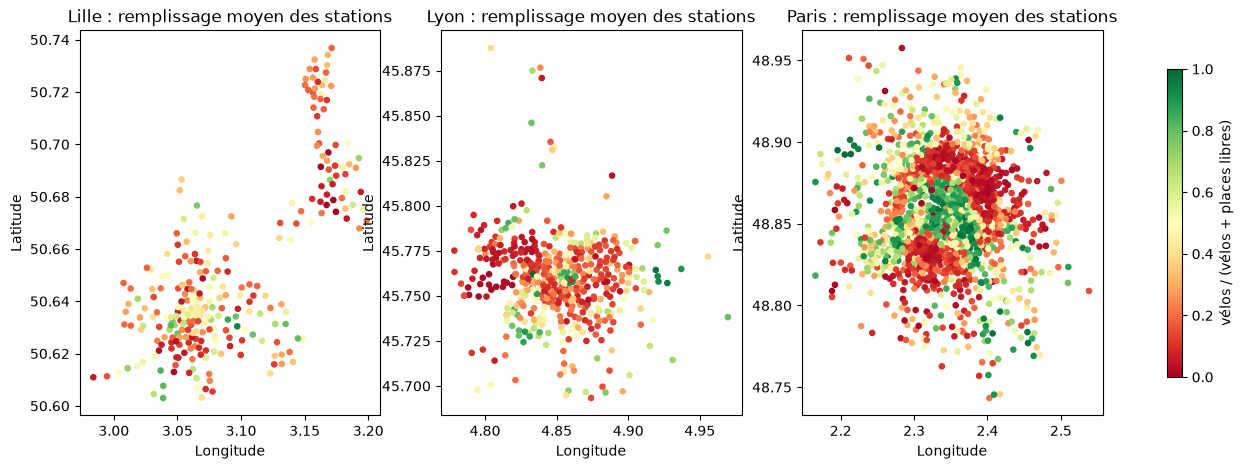

In [4]:
def distance_km(lat, lon, lat0, lon0):
    r = 6371.0
    p1, p2 = np.radians(lat), np.radians(lat0)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon0 - lon) / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

stations = silver.groupby("cle").agg(
    ville=("city_id", "first"), nom=("station_name", "first"), lat=("latitude", "first"), lon=("longitude", "first"),
    remplissage=("taux_remplissage", "mean"), releves=("taux_remplissage", "count"),
    vide=("bikes_available", lambda s: float((s.dropna() == 0).mean())),
    pleine=("free_slots", lambda s: float((s.dropna() == 0).mean())),
).dropna(subset=["lat", "lon", "remplissage"]).reset_index()
stations["dist_centre_km"] = [distance_km(r.lat, r.lon, cities[r.ville]["latitude"], cities[r.ville]["longitude"]) for r in stations.itertuples()]
stations["cellule"] = (np.floor(stations["lat"] / GRILLE_DEG).astype(int).astype(str) + "_" + np.floor(stations["lon"] / GRILLE_DEG).astype(int).astype(str))

cellules = stations.groupby(["ville", "cellule"]).agg(
    stations=("cle", "size"), remplissage=("remplissage", "mean"), vide=("vide", "mean"),
    lat=("lat", "mean"), lon=("lon", "mean"),
).reset_index()
fiables = cellules[cellules["stations"] >= 3]
print(f"{len(cellules)} cellules, dont {len(fiables)} avec au moins 3 stations.")
for ville, g in fiables.groupby("ville"):
    print(f"\nZones à l'offre la plus faible (remplissage moyen le plus bas) : {ville}")
    display(g.nsmallest(5, "remplissage")[["cellule", "stations", "remplissage", "vide", "lat", "lon"]].round(3).reset_index(drop=True))

# Déséquilibre centre / périphérie
for ville, g in stations.groupby("ville"):
    if len(g) >= 30 and g["dist_centre_km"].nunique() > 1:
        rho, p = stats.spearmanr(g["dist_centre_km"], g["remplissage"])
        print(f"{cities[ville]['name']} : remplissage et distance au centre, rho = {rho:+.2f} sur {len(g)} stations (p = {p:.1e}).")

fig, axes = plt.subplots(1, len(stations["ville"].unique()), figsize=(5.5 * len(stations["ville"].unique()), 5))
axes = np.atleast_1d(axes)
for ax, (ville, g) in zip(axes, stations.groupby("ville")):
    sc = ax.scatter(g["lon"], g["lat"], c=g["remplissage"], cmap="RdYlGn", vmin=0, vmax=1, s=14)
    ax.set_title(f"{cities[ville]['name']} : remplissage moyen des stations")
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
fig.colorbar(sc, ax=axes.tolist(), label="vélos / (vélos + places libres)", shrink=0.8)
plt.show()

## 4. Question 3 : pics d'utilisation journaliers

Profil par **heure locale** du remplissage moyen et de l'activité. Il n'est lisible que si la collecte couvre plusieurs jours ; le nombre d'heures du jour réellement observées est affiché.

In [5]:
silver["heure_locale"] = silver["observed_at_utc"].dt.tz_convert(FUSEAU).dt.hour
profil = silver.groupby("heure_locale").agg(
    remplissage=("taux_remplissage", "mean"), activite=("variation", "mean"), releves=("cle", "size"),
).reindex(range(24))
observees = int(profil["releves"].notna().sum())
print(f"Heures du jour observées : {observees} sur 24.")
if observees < 12:
    print("[ATTENTION] La collecte ne couvre pas assez d'heures du jour pour identifier des pics. Relancer après plusieurs jours de collecte.")
else:
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(profil.index, profil["remplissage"], marker="o", color="#2980b9", label="Remplissage moyen")
    ax.set_xlabel("Heure locale"); ax.set_ylabel("Remplissage moyen"); ax.set_xticks(range(24))
    ax2 = ax.twinx(); ax2.bar(profil.index, profil["activite"], alpha=0.25, color="#e67e22", label="Activité moyenne (vélos)")
    ax2.set_ylabel("Variation moyenne du stock par relevé")
    ax.set_title("Profil journalier du réseau (heure locale)")
    plt.show()
    pics = profil["activite"].nlargest(3)
    print("Heures les plus actives :", {int(h): round(float(v), 2) for h, v in pics.items()}, "(sur la période observée seulement)")
display(profil.dropna().round(3))

Heures du jour observées : 8 sur 24.
[ATTENTION] La collecte ne couvre pas assez d'heures du jour pour identifier des pics. Relancer après plusieurs jours de collecte.


,remplissage,activite,releves
heure_locale,,,
10,0.375,0.826,22470.0
11,0.374,0.356,26964.0
12,0.368,0.635,15729.0
13,0.361,0.59,24717.0
14,0.371,0.41,26964.0
15,0.368,0.461,24717.0
16,0.355,0.482,15729.0
17,0.357,1.397,6741.0


## 5. Question 5 : stations critiques nécessitant un rééquilibrage

Règle réglable : une station est **critique** si elle est vide ou pleine dans au moins `SEUIL_CRITIQUE` (30 %) de ses relevés valides, avec au moins `MIN_OBS` relevés. Tant que la collecte est courte, la règle est appliquée à titre provisoire avec le minimum de relevés disponible.

In [6]:
releves_max = int(stations["releves"].max()) if not stations.empty else 0
min_obs_effectif = MIN_OBS if releves_max >= MIN_OBS else max(2, releves_max)
if min_obs_effectif < MIN_OBS:
    print(f"[ATTENTION] Résultat provisoire : {releves_max} relevé(s) par station au maximum, règle appliquée avec {min_obs_effectif} au lieu de {MIN_OBS}.")
candidats = stations[stations["releves"] >= min_obs_effectif].copy()
candidats["critique_vide"] = candidats["vide"] >= SEUIL_CRITIQUE
candidats["critique_pleine"] = candidats["pleine"] >= SEUIL_CRITIQUE
critiques = candidats[candidats["critique_vide"] | candidats["critique_pleine"]]
print(f"Stations critiques : {len(critiques)} sur {len(candidats)} évaluées.")
resume = critiques.groupby("ville").agg(vides=("critique_vide", "sum"), pleines=("critique_pleine", "sum"), total=("cle", "size"))
display(resume)
display(critiques.sort_values(["vide", "pleine"], ascending=False)[["ville", "nom", "releves", "vide", "pleine", "dist_centre_km"]].head(15).round(2).reset_index(drop=True))

Stations critiques : 398 sur 2240 évaluées.


,vides,pleines,total
ville,,,
lille,37,1,38
lyon,119,19,138
paris,158,64,222


,ville,nom,releves,vide,pleine,dist_centre_km
0,paris,Place de la Bastille - Bourdon,73,1.0,0.0,1.26
1,paris,Colonel Fabien - Sallnave,73,1.0,0.0,6.15
2,paris,Gare du Stade,73,1.0,0.0,10.68
3,paris,Mairie du 3ème,73,1.0,0.0,1.12
4,paris,Rochechouart lamartine,73,1.0,0.0,2.31
5,paris,Filles Saint-Thomas - Place de la Bourse,73,1.0,0.0,1.64
6,paris,Station Tour de France,73,1.0,0.0,3.25
7,paris,Lacépède - Monge,73,1.0,0.0,1.41
8,paris,Pierre-Simon Girard - Paris,73,1.0,0.0,9.08
9,paris,Saint-Germain - Verdun,73,1.0,0.0,6.60


## 6. Croisement météo et vélos (Partie 4)

La table `city_hourly` contient, par ville et par heure UTC, le stock de vélos agrégé et la météo. L'analyse n'est lancée que si au moins 24 heures communes existent ; sinon le notebook affiche le diagnostic de couverture.

In [7]:
if STORAGE_MODE == "minio":
    import io
    resp = client.get_object(buckets["gold"], "kpis/city_hourly.parquet")
    ch = pd.read_parquet(io.BytesIO(resp.read())); resp.close(); resp.release_conn()
else:
    ch = pd.DataFrame()

if ch.empty:
    print("[ATTENTION] city_hourly indisponible : lancer le notebook 03.")
else:
    ch["hour_utc"] = pd.to_datetime(ch["hour_utc"], utc=True)
    print("Statuts de jointure :", ch["statut_jointure"].value_counts().to_dict())
    velos = ch.dropna(subset=["mobility_bikes_available", "weather_temperature_c"]).copy()
    velos["remplissage"] = velos["mobility_bikes_available"] / (velos["mobility_bikes_available"] + velos["mobility_free_slots"])
    print(f"Heures vélos et météo communes : {len(velos)}")
    if len(velos) < 24:
        print("[ATTENTION] Moins de 24 heures communes : aucune corrélation n'est calculée, elle ne serait pas défendable. "
              "Elle sera disponible après quelques jours de collecte CityBikes.")
    else:
        lignes = []
        for col, label in (("weather_precipitation_mm", "Pluie"), ("weather_temperature_c", "Température"),
                           ("weather_wind_speed_ms", "Vent")):
            sub = velos[["remplissage", col]].dropna()
            if len(sub) >= 24 and sub[col].nunique() > 1:
                rho, p = stats.spearmanr(sub[col], sub["remplissage"])
                lignes.append({"Météo": label, "rho": round(rho, 2), "p": f"{p:.1e}", "heures": len(sub)})
        display(pd.DataFrame(lignes))
        pluie = velos[velos["weather_precipitation_mm"] > 0]["remplissage"]; sec = velos[velos["weather_precipitation_mm"] <= 0]["remplissage"]
        if len(pluie) >= 5 and len(sec) >= 5:
            print(f"Remplissage médian : {pluie.median():.2f} avec pluie ({len(pluie)} h), {sec.median():.2f} sans pluie ({len(sec)} h).")
    triple = ch[ch["statut_jointure"].eq("complete_3_sources")]
    print(f"Heures où mobilité, pollution et météo coexistent : {len(triple)}")

Statuts de jointure : {'meteo_seule': 180067, 'pollution_et_meteo': 1034, 'complete_3_sources': 16, 'mobilite_et_meteo': 8, 'mobilite_seule': 3}
Heures vélos et météo communes : 24


,Météo,rho,p,heures
0,Pluie,-0.37,7.3e-02,24
1,Température,0.13,5.5e-01,24
2,Vent,0.71,1.1e-04,24


Remplissage médian : 0.33 avec pluie (11 h), 0.39 sans pluie (13 h).
Heures où mobilité, pollution et météo coexistent : 16


## 7. Synthèse et limites

- La collecte CityBikes tourne toutes les 5 minutes ; les résultats de ce notebook gagnent en fiabilité à mesure que la période s'allonge. Les messages `[ATTENTION]` indiquent les sections qui attendent encore des données.
- Les indicateurs d'usage reposent sur des variations de stock : ils signalent l'activité d'une station sans compter les trajets.
- Les conditions favorables à la mobilité douce se lisent dans la section 6 : une corrélation entre la pluie, la température et le remplissage n'est publiée qu'à partir de 24 heures communes.
- Relancer ce notebook après plusieurs jours de collecte, puis recopier les conclusions chiffrées dans les documents de rendu.

## 8. Extension historique CityBikes

Cette section relit les séries horaires produites par `scripts/citybikes_archive.py` et complète l'analyse du direct avec une période longue.


In [8]:
import io
import pyarrow.parquet as pq

COLONNES = ["city_id", "city_name", "network_id", "station_id", "station_name", "hour_utc", "bikes_available", "free_slots"]
CAPACITE_MAX = 150   # stations d'événements (festivals, hippodrome) écartées : 0,003 % des lignes


def fichiers_archive():
    if STORAGE_MODE == "minio":
        return sorted(o.object_name for o in client.list_objects(buckets["silver"], prefix="citybikes-archive/", recursive=True)
                      if o.object_name.endswith(".parquet"))
    return sorted(str(p) for p in (PROJECT_ROOT / "data" / "citybikes-archive" / "silver").glob("year=*/citybikes_stations_hourly*.parquet"))


def ouvrir(cle):
    if STORAGE_MODE == "minio":
        resp = client.get_object(buckets["silver"], cle)
        contenu = io.BytesIO(resp.read()); resp.close(); resp.release_conn()
        return pq.ParquetFile(contenu)
    return pq.ParquetFile(cle)


archive_paths = fichiers_archive()
profils, stations_agg = [], []
n_obs, debut, fin = 0, None, None
if not archive_paths:
    print("[ATTENTION] Aucune archive Silver trouvée (R2: citybikes-archive/ ; local: data/citybikes-archive/silver). Lancer scripts/citybikes_archive.py.")
else:
    # Un fichier à la fois, puis un bloc (un mois) à la fois : la mémoire reste bornée même pour Vélib'
    for cle in archive_paths:
        pf = ouvrir(cle)
        for groupe in range(pf.num_row_groups):
            h = pf.read_row_group(groupe, columns=COLONNES).to_pandas()
            h["capacity"] = h["bikes_available"] + h["free_slots"]
            h = h[h["capacity"] <= CAPACITE_MAX].copy()
            h["hour_utc"] = pd.to_datetime(h["hour_utc"], utc=True)
            h = h.sort_values(["station_id", "hour_utc"])
            ecart = h.groupby("station_id")["hour_utc"].diff()
            h["variation_abs"] = h.groupby("station_id")["bikes_available"].diff().abs().where(ecart == pd.Timedelta(hours=1))
            h["hour_local"] = h["hour_utc"].dt.tz_convert(FUSEAU).dt.hour
            h["fill_rate"] = h["bikes_available"] / h["capacity"].where(h["capacity"] > 0)
            profils.append(h.groupby(["city_id", "hour_local"]).agg(
                fill_sum=("fill_rate", "sum"), fill_n=("fill_rate", "count"),
                activity_proxy=("variation_abs", "sum"), observations=("station_id", "size")).reset_index())
            h["vide"] = h["bikes_available"].eq(0)
            h["pleine"] = h["free_slots"].eq(0)
            stations_agg.append(h.groupby(["city_id", "city_name", "network_id", "station_id", "station_name"], dropna=False).agg(
                observations=("station_id", "size"), vides=("vide", "sum"), pleines=("pleine", "sum")).reset_index())
            n_obs += len(h)
            debut = h["hour_utc"].min() if debut is None else min(debut, h["hour_utc"].min())
            fin = h["hour_utc"].max() if fin is None else max(fin, h["hour_utc"].max())
    print(f"Historique : {n_obs:,} observations horaires de station | {debut:%d/%m/%Y} au {fin:%d/%m/%Y} | {len(archive_paths)} fichiers")

Historique : 28,384,382 observations horaires de station | 01/11/2024 au 30/09/2026 | 9 fichiers


### Pics journaliers sur l'historique


In [9]:
if archive_paths:
    p = pd.concat(profils).groupby(["city_id", "hour_local"], as_index=False).sum()
    p["fill_rate"] = p["fill_sum"] / p["fill_n"]
    historical_profile = p[["city_id", "hour_local", "fill_rate", "activity_proxy", "observations"]]
    print("Cinq heures locales les plus actives par ville (activité = somme des variations horaires de vélos par station) :")
    display(historical_profile.sort_values(["city_id", "activity_proxy"], ascending=[True, False]).groupby("city_id").head(5).reset_index(drop=True))
    print("Taux de remplissage moyen par heure locale :")
    display(historical_profile.pivot(index="hour_local", columns="city_id", values="fill_rate").round(3))

Cinq heures locales les plus actives par ville (activité = somme des variations horaires de vélos par station) :


,city_id,hour_local,fill_rate,activity_proxy,observations
0,lille,8,0.380603,282167.0,140620
1,lille,17,0.375241,255700.0,144822
2,lille,18,0.383676,255615.0,144834
3,lille,19,0.392415,223724.0,143552
4,lille,7,0.393911,217063.0,139299
5,lyon,8,0.375670,862817.0,258680
6,lyon,17,0.352772,808301.0,259047
7,lyon,7,0.404264,748561.0,258678
8,lyon,18,0.372391,721163.0,259421
9,lyon,16,0.372521,650901.0,258522


Taux de remplissage moyen par heure locale :


city_id,lille,lyon,paris
hour_local,,,
0,0.420,0.461,0.415
1,0.423,0.469,0.418
2,0.426,0.472,0.422
3,0.427,0.473,0.426
4,0.427,0.475,0.429
5,0.423,0.469,0.428
6,0.416,0.457,0.424
7,0.394,0.404,0.403
8,0.381,0.376,0.372


### Stations critiques sur l'année disponible

Seuil : au moins 30 % des observations vides ou pleines, avec au moins 10 observations valides.


In [10]:
if archive_paths:
    # Une station = un identifiant (le nom varie en casse d'un mois à l'autre : « RUE CORNEILLE » et « Rue Corneille »)
    s = pd.concat(stations_agg).groupby(["city_id", "city_name", "network_id", "station_id"], dropna=False, as_index=False).agg(
        station_name=("station_name", "last"), observations=("observations", "sum"), vides=("vides", "sum"), pleines=("pleines", "sum"))
    s["empty_rate"] = s["vides"] / s["observations"]
    s["full_rate"] = s["pleines"] / s["observations"]
    s["critical_rate"] = s[["empty_rate", "full_rate"]].max(axis=1)
    s = s[~s["station_name"].astype(str).str.contains("TEST|MOBILE", case=False, regex=True)]   # stations techniques de l'opérateur
    critiques = s[(s["observations"] >= 10) & (s["critical_rate"] >= 0.30)]
    # Vide ou pleine plus de 95 % du temps : la station est probablement hors service, un rééquilibrage n'y changerait rien
    hors_service = critiques[critiques["critical_rate"] >= 0.95]
    a_reequilibrer = critiques[critiques["critical_rate"] < 0.95]
    print("Stations critiques sur l'historique (au moins 30 % des heures vides ou pleines), hors stations techniques :")
    display(critiques.groupby("city_id").size().rename("critiques").to_frame()
            .join(hors_service.groupby("city_id").size().rename("probablement_hors_service"))
            .join(a_reequilibrer.groupby("city_id").size().rename("a_reequilibrer"))
            .join(s.groupby("city_id").size().rename("stations")).fillna(0).astype(int))
    print("Dix stations les plus critiques à rééquilibrer, par ville (ni hors service, ni technique) :")
    display(a_reequilibrer.sort_values(["city_id", "critical_rate"], ascending=[True, False]).groupby("city_id").head(10)[
        ["city_name", "station_name", "observations", "empty_rate", "full_rate", "critical_rate"]].round(3).reset_index(drop=True))

Stations critiques sur l'historique (au moins 30 % des heures vides ou pleines), hors stations techniques :


,critiques,probablement_hors_service,a_reequilibrer,stations
city_id,,,,
lille,38,32,6,311
lyon,34,11,23,530
paris,65,27,38,1584


Dix stations les plus critiques à rééquilibrer, par ville (ni hors service, ni technique) :


,city_name,station_name,observations,empty_rate,full_rate,critical_rate
0,Lille,Laënnec,1607,0.825,0.000,0.825
1,Lille,REPUBLIQUE BEAUX ARTS,4445,0.401,0.001,0.401
2,Lille,ARTOIS,2508,0.357,0.025,0.357
3,Lille,Cité Marianne,9353,0.338,0.012,0.338
4,Lille,Delory Barbieux,10688,0.318,0.002,0.318
5,Lille,Marie Marrant,7828,0.310,0.104,0.310
6,Lyon,,2185,0.541,0.797,0.797
7,Lyon,DUPEUBLE / 8 MAI 1945,482,0.170,0.724,0.724
8,Lyon,FOURVIERE,932,0.570,0.181,0.570
9,Lyon,3033 - OL STADIUM ÉPHÉMÈRE,641,0.000,0.515,0.515
